# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [2]:
import pandas as pd
import numpy as np

url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv'
df = pd.read_csv(url)

print("First 5 Rows of the Dataset")
display(df.head())

print("Summary Statistics")
display(df.describe(include='all'))

First 5 Rows of the Dataset


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Summary Statistics


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,119390,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390,103050.000000,6797.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390,119390
unique,2,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,926
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-10-21
freq,79330,NaN,NaN,NaN,13877,NaN,NaN,NaN,NaN,NaN,...,104641,NaN,NaN,NaN,89613,NaN,NaN,NaN,75166,1461
mean,NaN,0.370416,104.011416,2016.156554,NaN,27.165173,15.798241,0.927599,2.500302,1.856403,...,NaN,86.693382,189.266735,2.321149,NaN,101.831122,0.062518,0.571363,NaN,NaN
std,NaN,0.482918,106.863097,0.707476,NaN,13.605138,8.780829,0.998613,1.908286,0.579261,...,NaN,110.774548,131.655015,17.594721,NaN,50.535790,0.245291,0.792798,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,6.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,18.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.000000,2.000000,...,NaN,9.000000,62.000000,0.000000,NaN,69.290000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,69.000000,2016.000000,NaN,28.000000,16.000000,1.000000,2.000000,2.000000,...,NaN,14.000000,179.000000,0.000000,NaN,94.575000,0.000000,0.000000,NaN,NaN
75%,NaN,1.000000,160.000000,2017.000000,NaN,38.000000,23.000000,2.000000,3.000000,2.000000,...,NaN,229.000000,270.000000,0.000000,NaN,126.000000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. One of the things that stands out in the initial preview is how many NaN is within the summary statistics. While I do know that this is dependent on the type of data and type of summary statistic we are doing, it is still not clean on the eyes to digest. As far as any rows/columns that seem unusual, I noticed that some of the agent and company values may be missing as it does not add up to the count the rest of the columns have.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [3]:
from sklearn.preprocessing import StandardScaler

features = ['is_repeated_guest', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'lead_time']

df_prep = df[features].copy()

df_prep = df_prep.drop_duplicates()
df_prep = df_prep.dropna()

q_limit_waiting = df_prep['days_in_waiting_list'].quantile(0.99)
q_limit_lead = df_prep['lead_time'].quantile(0.99)

df_prep = df_prep[
    (df_prep['days_in_waiting_list'] <= q_limit_waiting) &
    (df_prep['lead_time'] <= q_limit_lead)
]

scaler = StandardScaler()
scale_cols = ['lead_time', 'days_in_waiting_list']

df_prep[scale_cols] = scaler.fit_transform(df_prep[scale_cols])

print("Preprocessed DataFrame Info:")
print(df_prep.info())
print("\nFirst 5 Rows of Prepared Data:")
display(df_prep.head())

Preprocessed DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
Index: 1850 entries, 0 to 117040
Data columns (total 4 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   is_repeated_guest               1850 non-null   int64  
 1   previous_bookings_not_canceled  1850 non-null   int64  
 2   days_in_waiting_list            1850 non-null   float64
 3   lead_time                       1850 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 72.3 KB
None

First 5 Rows of Prepared Data:


,is_repeated_guest,previous_bookings_not_canceled,days_in_waiting_list,lead_time
0,0,0,-0.370655,1.747767
2,0,0,-0.370655,-0.936152
3,0,0,-0.370655,-0.888082
4,0,0,-0.370655,-0.880070
6,0,0,-0.370655,-0.992234


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. The features I selected were is_repeated_guest, previous_bookings_not_canceled, days_in_waiting_list, and lead_time. I selected these as I was curious if there was some sort of relationship between how far a guest booked in advance and if that was caused by if they have booked before, have continuously canceled their bookings, and what all of these have to do with waiting lists.

2. I expect to find that there would be a positive correlation between if they are a repeated guest and the number of previous bookings not canceled as well as the hotels demand by comparing the lead time with the number of days between when a booking is booked and when it is confirmed.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

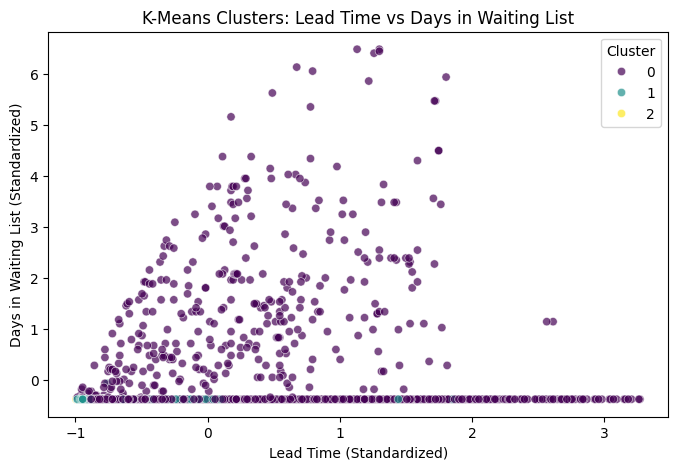

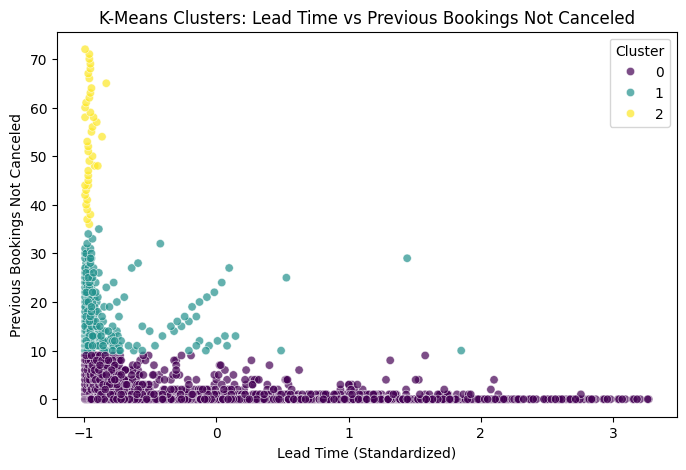


--- Cluster Averages Summary Table ---


,is_repeated_guest,previous_bookings_not_canceled,days_in_waiting_list,lead_time
Cluster,,,,
0,0.314449,1.397836,0.064858,0.146269
1,0.790795,17.326360,-0.364291,-0.801529
2,1.000000,53.700000,-0.370655,-0.955580


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(df_prep)

df_prep["Cluster"] = clusters

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_prep, x='lead_time', y='days_in_waiting_list', hue='Cluster', palette='viridis', alpha=0.7)
plt.title('K-Means Clusters: Lead Time vs Days in Waiting List')
plt.xlabel('Lead Time (Standardized)')
plt.ylabel('Days in Waiting List (Standardized)')
plt.legend(title='Cluster')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_prep, x='lead_time', y='previous_bookings_not_canceled', hue='Cluster', palette='viridis', alpha=0.7)
plt.title('K-Means Clusters: Lead Time vs Previous Bookings Not Canceled')
plt.xlabel('Lead Time (Standardized)')
plt.ylabel('Previous Bookings Not Canceled')
plt.legend(title='Cluster')
plt.show()

summary_table = df_prep.groupby('Cluster').mean()
print("\n--- Cluster Averages Summary Table ---")
display(summary_table)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. The k value that I chose was 3, and I decided on this because starting with a smaller number of plot points and seeing how those clusters work around each other is great for knowledge.

2. For cluster 0, the type of customer would be fist-time or casual travels. The variables that are most important or prominent for that cluster are the lead_time and is_repeated_guest. For cluster 1, the types of customers are the customers that regularly stay at hotels and travel. The most prominent and important variables for this cluster are is_repeated_guest, previous_bookings_not_canceled, and lead_time. The last cluster, Cluster 2, has the customers that travel a significant amount and frequently book hotel stays. The most prominent and important variables for this cluster are previous_bookings_not_canceled, and is_repeated_guest.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

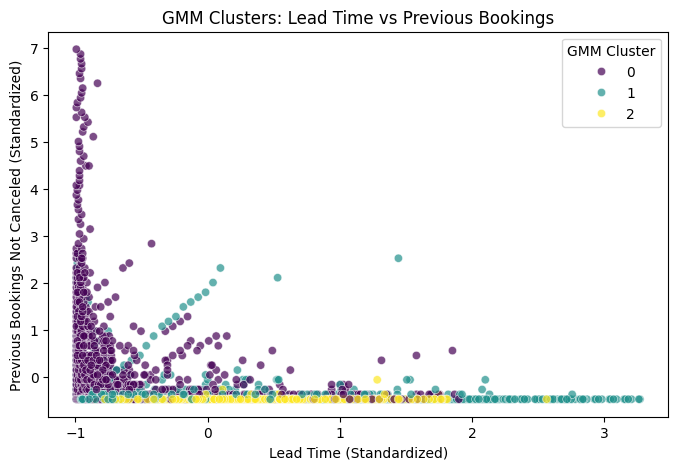

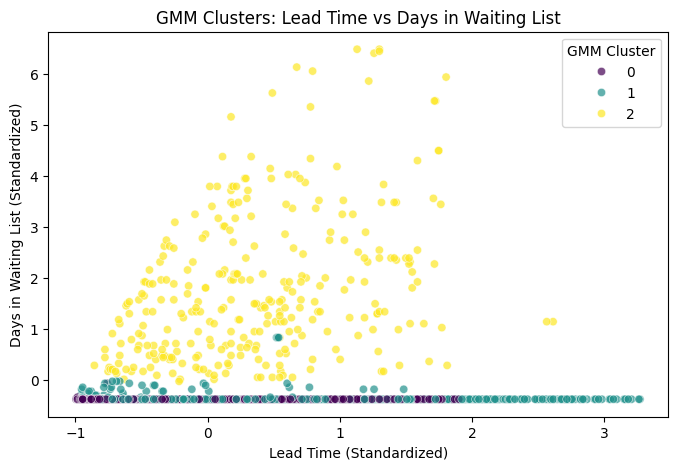


--- GMM Cluster Averages Summary Table ---


,is_repeated_guest,previous_bookings_not_canceled,days_in_waiting_list,lead_time,count
GMM_Cluster,,,,,
0,1.248512,0.512005,-0.370111,-0.524304,717
1,-0.800953,-0.269043,-0.355378,0.315379,822
2,-0.761414,-0.469307,1.792573,0.375191,311


In [3]:
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

features = ['is_repeated_guest', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'lead_time']

try:
    X = df_prep[features].copy()
except NameError:
    url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv'
    df = pd.read_csv(url)
    df_prep_backup = df[features].copy().drop_duplicates().dropna()
    q_limit_waiting = df_prep_backup['days_in_waiting_list'].quantile(0.99)
    q_limit_lead = df_prep_backup['lead_time'].quantile(0.99)
    df_prep_backup = df_prep_backup[
        (df_prep_backup['days_in_waiting_list'] <= q_limit_waiting) &
        (df_prep_backup['lead_time'] <= q_limit_lead)
    ]
    X = df_prep_backup.copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

gmm = GaussianMixture(n_components=3, random_state=42)
gmm_fit = gmm.fit_predict(X_scaled)

df_gmm = pd.DataFrame(X_scaled, columns=features)
df_gmm["GMM_Cluster"] = gmm_fit

probs = gmm.predict_proba(X_scaled)
df_gmm["Prob_Cluster_0"] = probs[:, 0]
df_gmm["Prob_Cluster_1"] = probs[:, 1]
df_gmm["Prob_Cluster_2"] = probs[:, 2]

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_gmm,
    x="lead_time",
    y="previous_bookings_not_canceled",
    hue="GMM_Cluster",
    palette="viridis",
    alpha=0.7,
)
plt.title("GMM Clusters: Lead Time vs Previous Bookings")
plt.xlabel("Lead Time (Standardized)")
plt.ylabel("Previous Bookings Not Canceled (Standardized)")
plt.legend(title="GMM Cluster")
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_gmm,
    x="lead_time",
    y="days_in_waiting_list",
    hue="GMM_Cluster",
    palette="viridis",
    alpha=0.7,
)
plt.title("GMM Clusters: Lead Time vs Days in Waiting List")
plt.xlabel("Lead Time (Standardized)")
plt.ylabel("Days in Waiting List (Standardized)")
plt.legend(title="GMM Cluster")
plt.show()

gmm_summary = df_gmm.groupby("GMM_Cluster")[features].mean()
gmm_summary["count"] = df_gmm.groupby("GMM_Cluster").size()
print("\n--- GMM Cluster Averages Summary Table ---")
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. The GMM results compared to the KMeans results as the GMM grouped all of the repeated guests into one cluster as opposed to grouping them by past booking history like KMeans did.

2. Where are the operational bottlenecks and the non-standard behaviors occuring? What types of customers show mixed and/or overlapping traits?


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [8]:
import numpy as np
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.cluster import KMeans
import pandas as pd

try:
    _ = df_prep
except NameError:
    if 'df_prep_backup' in globals():
        df_prep = df_prep_backup.copy()
    else:
        url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv'
        df = pd.read_csv(url)
        df_prep = df[features].copy().drop_duplicates().dropna()
        q_limit_waiting = df_prep['days_in_waiting_list'].quantile(0.99)
        q_limit_lead = df_prep['lead_time'].quantile(0.99)
        df_prep = df_prep[
            (df_prep['days_in_waiting_list'] <= q_limit_waiting) &
            (df_prep['lead_time'] <= q_limit_lead)
        ]

try:
    if 'Cluster' not in df_prep.columns:
        df_prep['Cluster'] = kmeans.predict(X_scaled)
    kmeans_wcss = kmeans.inertia_
except (NameError, KeyError):
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    df_prep["Cluster"] = kmeans.fit_predict(X_scaled)
    kmeans_wcss = kmeans.inertia_

kmeans_silhouette = silhouette_score(X_scaled, df_prep["Cluster"])
kmeans_db = davies_bouldin_score(X_scaled, df_prep["Cluster"])

gmm_labels = df_gmm["GMM_Cluster"].values
gmm_centers = gmm.means_
gmm_wcss = np.sum((X_scaled - gmm_centers[gmm_labels])** 2)

gmm_silhouette = silhouette_score(X_scaled, gmm_labels)
gmm_db_index = davies_bouldin_score(X_scaled, gmm_labels)

metrics_df = pd.DataFrame(
    {
        "Model": ["K-Means", "GMM"],
        "WCSS (Inertia)": [kmeans_wcss, gmm_wcss],
        "Silhouette Score": [kmeans_silhouette, gmm_silhouette],
        "Davies-Bouldin Index": [kmeans_db, gmm_db_index]
    }
)
display(metrics_df)

,Model,WCSS (Inertia),Silhouette Score,Davies-Bouldin Index
0,K-Means,3479.030623,0.460913,0.899405
1,GMM,3734.798115,0.409936,1.071488


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. Based on the metrics, the KMeans model perfomed better as it had a lower WCSS score, a higher silhouette score, and a lower davies-bouldin index.

5.3. I would recommend the KMeans model for a business analyst to use as not only did it have a better statistical performance across the board, but it created clearer, more mutually exclusive groups which makes it much easier for more teams in a business to learn from this so they can come up with business strategies in response.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [10]:
features = ['is_repeated_guest', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'lead_time']

cluster_summary = df_prep.groupby("Cluster")[features].mean()

sorted_cluster_summary = cluster_summary.sort_values(by="previous_bookings_not_canceled", ascending=False)

print("\n--- Sorted Cluster Summary (by Previous Bookings Not Canceled) ---")
display(sorted_cluster_summary)


--- Sorted Cluster Summary (by Previous Bookings Not Canceled) ---


,is_repeated_guest,previous_bookings_not_canceled,days_in_waiting_list,lead_time
Cluster,,,,
1,0.984952,9.752394,0.172367,57.972640
0,0.001071,1.444325,3.421842,161.563169
2,0.010811,0.037838,77.081081,193.735135


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. In terms of guest behavior, cluster 1 represents the repeat guests. Cluster 0 represents the guests who book hotels for leisure or typical vacationers who have little to no relationship with the hotel and plan their trips far ahead of time. The last cluster, cluster 2 represents high-demand and peak-season bookers.

2. The hotel could tailor services or promotions to cluster 1 by creating loyalty perks and recognition via room upgrades, messages, and/or other rewards to maintain loyalty. They can also do targeted promotions via email and discounts, as well as help them re-book easier. For cluster 0, they can give them discounts for booking earlier, help them plan their stay with customer service representatives, and make the penalites more flexible surrounding their cancellation or rebooking policies. For cluster 2, they can keep regular communication with them active to retain guests, introduce perks or special offers when a guest finally does get off the wait list, and if the date they are booking for is in "peak" season help them find alternative dates.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1.

2.

3.

4.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"